# Statistical Model Checking for Kappa Models

This notebook demonstrates the statistical model checking workflow proposed in the paper. A BLTL property is used to instrument a Kappa model, generate stochastic trajectories with KaSim, monitor individual traces, and estimate the probability of property satisfaction.

Given a Kappa model and a bounded linear temporal logic (BLTL) property, the workflow:

1. extracts the atomic propositions from the formula;
2. instruments the Kappa model to record their truth values;
3. generates stochastic trajectories with KaSim;
4. evaluates the BLTL formula on each trajectory;
5. estimates its satisfaction probability through repeated simulations.

The notebook first illustrates the procedure on one trajectory and then performs statistical model checking.

In [1]:
from pathlib import Path
import os
import matplotlib.pyplot as plt

from kappa_smc.simulation import SimulationConfig, KappaSimulator
from kappa_smc.estimation import KappaSMC, SMCConfig

### Kappa installation path

Before running the notebook, set `KAPPA_BIN_PATH` to the directory containing the Kappa executables on your computer, in particular `KappaSwitchman` and `KaSim`.

In [ ]:
# KAPPA_BIN_PATH = "/Users/username/MYKappa/Kappapp.app/Contents/Resources/bin"
# KAPPA_BIN_PATH = r"C:\Users\username\AppData\Local\opam\default\bin"
KAPPA_BIN_PATH = ""

current_dir = Path.cwd()
REPO_ROOT = current_dir.parent if current_dir.name == "notebooks" else current_dir

## Property preprocessing

BLTL formulas are supplied as strings using the constructors `AP`, `Not`, `And`,
`Or`, `G_leq`, `F_leq`, and `Until_leq`.

For example:

```python
And(
    G_leq(50, AP("I<80")),
    F_leq(50, AP("I<2"))
)
```

**Note:** the implementation currently supports only strict '<' and '>' (<= and >= can be expressed using negation).

## Example: stable consensus

We demonstrate the statistical model checking workflow on a collective decision-making model in which agents can support one of two alternatives, $x$ and $y$, or remain undecided. A fixed number of zealots permanently support one alternative and influence the evolution of the ordinary agents.

The observables `X`, `Y`, and `U` describe the population associated with the two alternatives and the undecided state. The Boolean observables `con_x` and `con_y` indicate whether the corresponding alternative satisfies the majority and decision-distance conditions defined in the Kappa model.

We consider the BLTL property

$$
\Phi_h =
F_{\leq 35}G_{\leq h}\,\mathit{consensus}_x
\;\lor\;
F_{\leq 35}G_{\leq h}\,\mathit{consensus}_y .
$$

The property is satisfied when consensus on one of the two alternatives is reached within $35$ time units and the same consensus is then maintained for at least $h$ additional time units.

The outer disjunction is intentional: it requires one fixed alternative to remain in consensus throughout the holding interval, rather than allowing the system to switch between $x$- and $y$-consensus.

We first inspect one stochastic trajectory and then estimate the satisfaction probability from multiple independent simulations together with a 95% Wilson confidence interval.

In [4]:
# Experiment configuration

MODEL_PATH = REPO_ROOT/"models"/"consensus.ka"

REACHABILITY_BOUND = 35
HOLDING_TIME = 5

FORMULA = (
    "Or("
    f'F_leq({REACHABILITY_BOUND}, G_leq({HOLDING_TIME}, AP("consensus_x>0"))),'
    f'F_leq({REACHABILITY_BOUND}, G_leq({HOLDING_TIME}, AP("consensus_y>0")))'
    ")"
)

simulation_config = SimulationConfig(
    max_time=REACHABILITY_BOUND + HOLDING_TIME,
    plot_period=1,
)

simulator = KappaSimulator(kappa_bin_path=KAPPA_BIN_PATH,config=simulation_config)

smc = KappaSMC(simulator=simulator)

prepared_property = smc.prepare(model_path=MODEL_PATH,formula_source=FORMULA)

print("BLTL formula:")
print(FORMULA)

print("\nAtomic propositions:")

for index, proposition in enumerate(prepared_property.atomic_propositions):
    print(f"  p_{index}: {proposition}")

BLTL formula:
Or(F_leq(35, G_leq(5, AP("consensus_x>0"))),F_leq(35, G_leq(5, AP("consensus_y>0"))))

Atomic propositions:
  p_0: consensus_x>0
  p_1: consensus_y>0


### Monitoring one trajectory

A single stochastic trajectory is generated and monitored first. This provides a qualitative view of the consensus
dynamics and makes it possible to inspect the observables introduced for the atomic propositions.

The first plot shows the evolution of the population variables. The second shows when the consensus conditions for alternatives \(x\) and \(y\) are satisfied. The BLTL monitor then determines whether either condition remains continuously true for the required holding time.

AP: 7/41 time points true
G_leq: 0/41 time points true
F_leq: 0/41 time points true
AP: 0/41 time points true
G_leq: 0/41 time points true
F_leq: 0/41 time points true
Or: 0/41 time points true

Formula holds at t=0: False
         [T] |            X |           Zx |           Zy |            Y |            U |        con_x |        con_y |          p_0 |          p_1
---------------------------------------------------------------------------------------------------------------------------------------------------
       0.000 |       50.000 |       24.000 |       24.000 |       50.000 |        0.000 |        0.000 |        0.000 |        0.000 |        0.000
       1.000 |       44.000 |       24.000 |       24.000 |       49.000 |        7.000 |        0.000 |        0.000 |        0.000 |        0.000
       2.000 |       42.000 |       24.000 |       24.000 |       47.000 |       11.000 |        0.000 |        0.000 |        0.000 |        0.000
       3.000 |       42.000 |       2

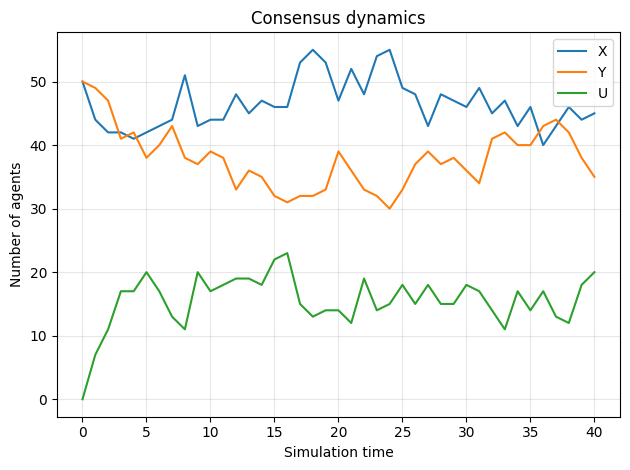

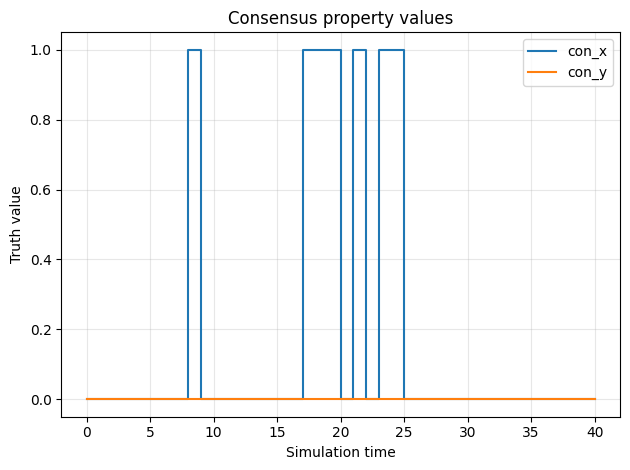

In [8]:
single_trace = smc.run_trace(prepared_property,verbose_monitor=True)

single_trace.print_results_table(max_rows=200)
single_trace.plot(variables=["X", "Y", "U"],title="Consensus dynamics",ylabel="Number of agents");
single_trace.plot(variables=["con_x", "con_y"],title="Consensus property values",ylabel="Truth value",step=True);

## Statistical model checking

A single trajectory illustrates one possible system evolution but does not quantify the probability of stable consensus. We therefore generate multiple independent stochastic trajectories and evaluate the BLTL property on each one.
Each trajectory produces a Bernoulli outcome:

$$
Y_i =
\begin{cases}
1, & \text{if trajectory \(i\) satisfies } \Phi_h,\\
0, & \text{otherwise}.
\end{cases}
$$

The satisfaction probability is estimated by

$$
\widehat{p}_h = \frac{1}{n}\sum_{i=1}^{n}Y_i,
$$

where $n$ is the number of simulated trajectories.

The displayed intermediate values show how the estimate evolves as additional simulations are completed. The figure reports the point estimate $\widehat{p}$ together with a 95% Wilson confidence interval. The interval represents the statistical uncertainty resulting from the finite number of simulated trajectories.

[10/100] p_hat = 0.2000
[20/100] p_hat = 0.2500
[30/100] p_hat = 0.3000
[40/100] p_hat = 0.2750
[50/100] p_hat = 0.3000
[60/100] p_hat = 0.3000
[70/100] p_hat = 0.3429
[80/100] p_hat = 0.3625
[90/100] p_hat = 0.3556
[100/100] p_hat = 0.3300

Final SMC result
----------------
Successes: 33/100
Estimated probability: 0.3300
95% Wilson confidence interval: [0.2456, 0.4269]
Elapsed time: 30.90 seconds


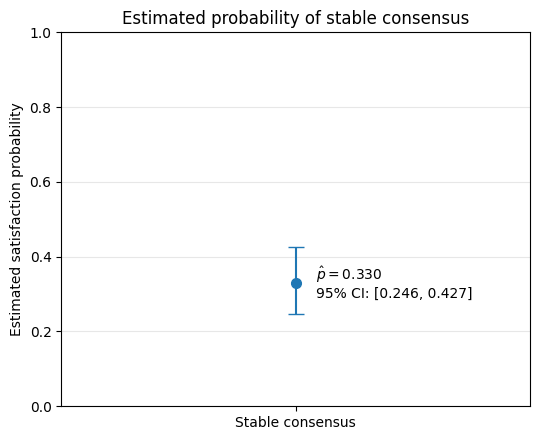

In [6]:
smc_config = SMCConfig(
    runs=100,
    progress_every=10,
    confidence_level=0.95,
)

smc_result = smc.run_smc(prepared_property,smc_config)
confidence_lower, confidence_upper = smc_result.confidence_interval

print("\nFinal SMC result")
print("----------------")
print(f"Successes: {smc_result.successes}/{smc_result.runs}")
print(f"Estimated probability: {smc_result.estimated_probability:.4f}")
print(f"95% Wilson confidence interval: [{confidence_lower:.4f}, {confidence_upper:.4f}]")
print(f"Elapsed time: {smc_result.elapsed_seconds:.2f} seconds")

fig, ax = smc_result.plot(
    label="Stable consensus",
    title="Estimated probability of stable consensus",
)

plt.show()